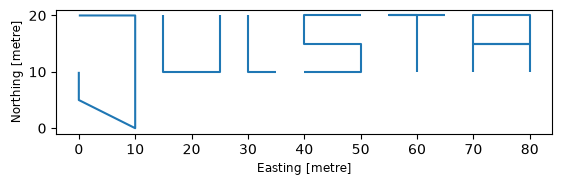

In [6]:
# Stwórz warstwę liniową, która po wyświetleniu będzie zawierała pierwsze 3 drukowane litery Twojego imienia 
# i pierwsze 3 drukowane litery Twojego nazwiska. Każda literka powinna być osobnym rekordem w GeoDataFrame. 
# Wyeksportuj te dane i wyświetl w QGIS.

from shapely import Point, LineString, Polygon
import geopandas as gpd

lineJ = LineString([
    (0,10),
    (0,5),
    (10,0),
    (10,20),
    (0,20)
])

lineU = LineString([
    (25, 20),
    (25, 10),
    (15, 10),
    (15, 20)
])

lineL = LineString([
    (35, 10),
    (30, 10),
    (30, 20)
])

lineS = LineString([
    (40, 10),
    (50, 10),
    (50, 15),
    (40, 15),
    (40, 20),
    (50, 20)
])

lineT = LineString([
    (60, 10),
    (60, 20),
    (55, 20),
    (65, 20)
])

lineA = LineString([
    (80, 10),
    (80, 20),
    (70, 20),
    (70, 15),
    (80, 15),
    (70, 15),
    (70, 10)
])

plot = gpd.GeoDataFrame(geometry=[lineJ, lineU, lineL, lineS, lineT, lineA], crs="EPSG:2180")
plot.plot()

#Zapisanie pliku do formatu .gpkg
plot.to_file("C:/Users/julia/Desktop/SDG/imie_nazwisko.gpkg", driver="GPKG", layer="imie_nazwisko")

In [ ]:
# Z danych o wyspach stwórz słownik, gdzie kluczem będą nazwy krajów a wartością lista geometrii wysp do nich przypisanych.
# Następnie stwórz ranking top 10 krajów które mają największą sumaryczną powierzchnię wysp w m2

path_to_files = "C:/Users/julia/Desktop/SDG/cwiczenia/dane/"

islands = gpd.read_file(path_to_files + "fw2.geojson")
islands

islands_dict = {}
for country in islands["państwo"].unique():
    islands_dict[country] = islands[islands["państwo"] == country].geometry.tolist()

islands_dict




{'Cypr': [<MULTIPOLYGON (((34.11 35.395, 33.974 35.321, 33.973 35.321, 33.973 35.321, ...>],
 'Kanada\n': [<MULTIPOLYGON (((-94.406 75.751, -94.583 75.746, -94.629 75.746, -94.676 75....>,
  <MULTIPOLYGON (((-53.713 48.149, -53.686 48.147, -53.668 48.151, -53.648 48....>],
 'Kanada': [<MULTIPOLYGON (((-89.989 73.988, -90.008 73.985, -90.058 73.992, -90.159 74....>,
  <MULTIPOLYGON (((-61.091 45.55, -61.02 45.575, -60.937 45.577, -60.904 45.57...>,
  <MULTIPOLYGON (((-103.057 78.12, -103.114 78.118, -103.194 78.119, -103.213 ...>,
  <MULTIPOLYGON (((-95.224 77.167, -95.245 77.164, -95.291 77.165, -95.314 77....>,
  <MULTIPOLYGON (((-79.541 62.411, -79.446 62.381, -79.429 62.358, -79.421 62....>,
  <MULTIPOLYGON (((-76.811 63.601, -76.711 63.566, -76.672 63.529, -76.676 63....>,
  <MULTIPOLYGON (((-70.712 62.815, -70.66 62.798, -70.588 62.774, -70.547 62.7...>,
  <MULTIPOLYGON (((-75.583 68.3, -75.562 68.294, -75.454 68.267, -75.43 68.262...>,
  <MULTIPOLYGON (((-96.768 78.684, -96.709 7

74     0
207    0
214    0
dtype: int32
74     0
207    0
214    0
dtype: int32
74     0
207    0
214    0
dtype: int32


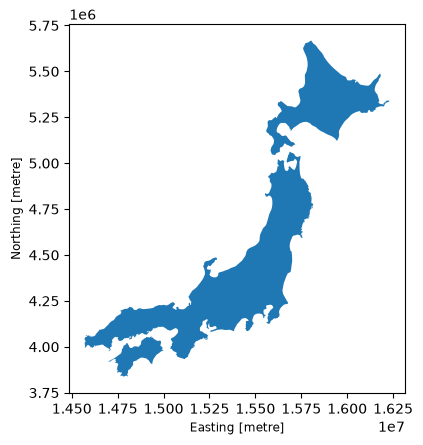

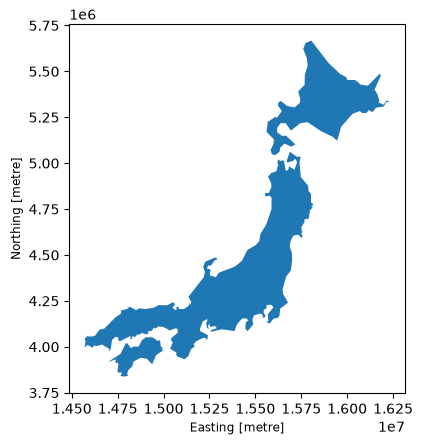

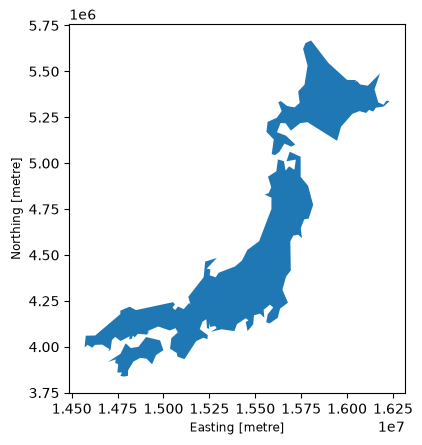

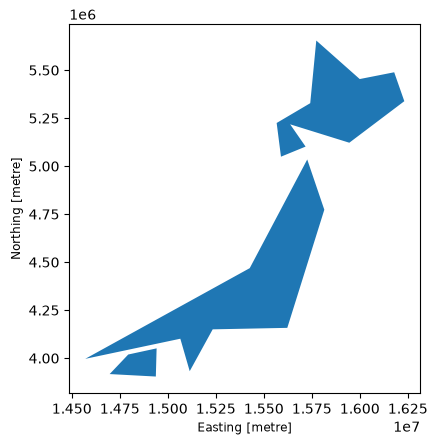

In [ ]:
# Z danych o wyspach stwórz nowy GeoDataFrame zawierający tylko wyspy należące do Japonii. 
# Przeprowadź dla nich 3 wizualizacje różniące się poziomem uproszczenia geometrii. 
# Dla każdego poziomu wypisz: ilość krawędzi (linii) oraz ilość wierzchołków (punktów) z których się składa

islands = gpd.read_file(path_to_files + "fw2.geojson")

islands_Japan = islands[islands["państwo"] == "Japonia"]
islands_Japan

not_simplified = islands_Japan.to_crs("3395")

simplify1 = not_simplified.simplify(5000)
simplify2 = not_simplified.simplify(10000)
simplify3 = not_simplified.simplify(100000)

not_simplified.plot()
simplify1.plot()
simplify2.plot()
simplify3.plot()
